<div style="background: linear-gradient(120deg, #3b1e54 0%, #8a2a6b 62%, #d6336c 100%); color: #ffffff; padding: 30px 34px; border-radius: 14px; margin: 4px 0 10px 0;">
<div style="font-size: 0.8em; letter-spacing: 0.16em; text-transform: uppercase; opacity: 0.85;">Statistical Methods · GSSI · Lecture 4 · 25/11</div>
<div style="font-size: 2.7em; font-weight: 800; line-height: 1.1; margin: 10px 0 8px 0;">Point estimation</div>
<div style="font-size: 1.15em; opacity: 0.95;">From noisy data to the best number, and how to know it deserves your trust.</div>
</div>

**Reading** · G. Benato, *Statistical Methods for Astroparticle Physics* (GSSI lecture notes), chapter 6.

**In this lecture**

1. [Inference and estimators](#s1)
2. [Properties of estimators](#s2)
3. [Maximum likelihood](#s3)
4. [Extended likelihood](#s4)
5. [Binned likelihood](#s5)
6. [The $\chi^2$ (least squares) method](#s6)
7. [Fitting histograms](#s7)
8. [In practice](#s8)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats

# --- house style: one palette for every figure ------------------------------------
PLUM, FUCHSIA, TEAL, AMBER, GREY = "#3b1e54", "#d6336c", "#0b7285", "#e8890c", "#6b7280"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.prop_cycle": cycler(color=[FUCHSIA, PLUM, TEAL, AMBER]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": "#2a1a3a", "text.color": "#2a1a3a",
    "xtick.color": GREY, "ytick.color": GREY, "lines.linewidth": 2.0,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10,
})
rng = np.random.default_rng(2026)   # fixed seed: every run gives the same figures

---
## 1. Inference and estimators <a id="s1"></a>

**Inference** lets two worlds talk to each other: the world of the theory (the model), and the world of the data.

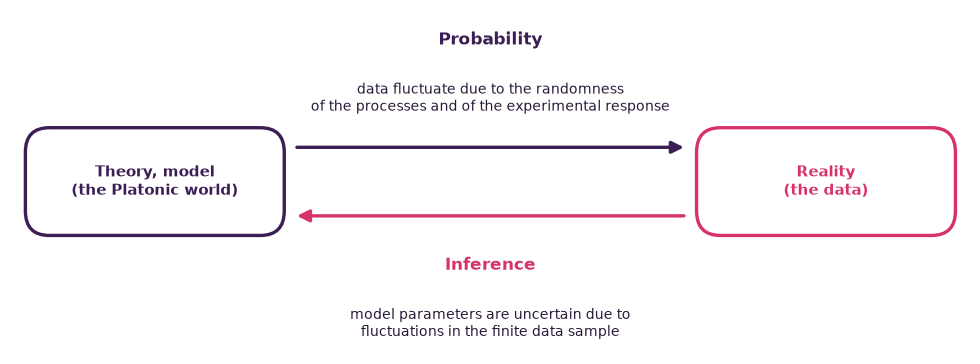

In [2]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8.8, 3.2), constrained_layout=True)
ax.set(xlim=(0, 10), ylim=(0, 3.5))
ax.axis("off")

def node(x, y, text, color):
    ax.add_patch(FancyBboxPatch((x - 1.3, y - 0.5), 2.6, 1.0, boxstyle="round,pad=0.05,rounding_size=0.25",
                                fc="white", ec=color, lw=2.2))
    ax.text(x, y, text, ha="center", va="center", color=color, fontweight="bold")

node(1.5, 1.75, "Theory, model\n(the Platonic world)", PLUM)
node(8.5, 1.75, "Reality\n(the data)", FUCHSIA)
ax.annotate("", xy=(7.05, 2.1), xytext=(2.95, 2.1), arrowprops=dict(arrowstyle="-|>", color=PLUM, lw=2.2, mutation_scale=16))
ax.annotate("", xy=(2.95, 1.4), xytext=(7.05, 1.4), arrowprops=dict(arrowstyle="-|>", color=FUCHSIA, lw=2.2, mutation_scale=16))
ax.text(5, 3.15, "Probability", ha="center", color=PLUM, fontweight="bold", fontsize=11)
ax.text(5, 2.6, "data fluctuate due to the randomness\nof the processes and of the experimental response", ha="center", va="center", fontsize=9)
ax.text(5, 0.85, "Inference", ha="center", color=FUCHSIA, fontweight="bold", fontsize=11)
ax.text(5, 0.3, "model parameters are uncertain due to\nfluctuations in the finite data sample", ha="center", va="center", fontsize=9)
plt.show()

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Estimate and estimator**

The **estimate** of a model's parameter is a mathematical procedure to determine its "central value" as a function of the data. The function of the data that returns the estimate is called the **estimator**. For example, if I measure the mass of an object once, $\hat{m}(x) = x$.

</div>

---
## 2. Properties of estimators <a id="s2"></a>

What makes an estimator good? Four properties: **consistency**, **unbiasedness**, **efficiency** (information content) and **robustness**.

### Consistency

An estimator is consistent if it converges in probability to the true value $\theta_t$:

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Consistency**

$$\forall\,\epsilon > 0:\quad \lim_{n\to\infty} P\big(|\hat\theta_n - \theta_t| < \epsilon\big) = 1$$

or, equivalently, $\forall\,\epsilon > 0,\ \eta > 0$ there is an $\tilde{n}$ such that $\;P\big(|\hat\theta_n - \theta_t| > \epsilon\big) < \eta \;\;\; \forall\, n > \tilde{n}$. Here $n$ is the number of measurements.

</div>

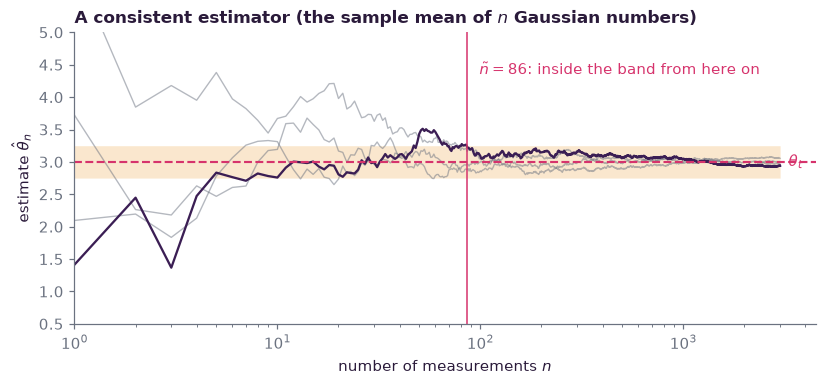

In [3]:
theta_t, sigma, n_max, eps = 3.0, 2.0, 3000, 0.25
n = np.arange(1, n_max + 1)
runs = np.cumsum(rng.normal(theta_t, sigma, (4, n_max)), axis=1) / n          # estimator: the sample mean
n_tilde = n[np.where(np.abs(runs[0] - theta_t) > eps)[0].max()] + 1

fig, ax = plt.subplots(figsize=(7.4, 3.4), constrained_layout=True)
ax.fill_between(n, theta_t - eps, theta_t + eps, color=AMBER, alpha=0.2, lw=0)
for r in runs[1:]:
    ax.plot(n, r, color=GREY, lw=0.9, alpha=0.5)
ax.plot(n, runs[0], color=PLUM, lw=1.5)
ax.axhline(theta_t, color=FUCHSIA, ls="--", lw=1.4)
ax.axvline(n_tilde, color=FUCHSIA, lw=1)
ax.text(n_tilde * 1.15, 4.35, rf"$\tilde{{n}} = {n_tilde}$: inside the band from here on", color=FUCHSIA)
ax.text(n_max * 1.1, theta_t, r"$\theta_t$", color=FUCHSIA, va="center")
ax.set(xscale="log", xlim=(1, n_max * 1.5), ylim=(0.5, 5), xlabel="number of measurements $n$", ylabel=r"estimate $\hat\theta_n$")
ax.set_title(r"A consistent estimator (the sample mean of $n$ Gaussian numbers)", loc="left")
plt.show()

### Bias

The **bias** is the expectation value of the deviation of the estimate from the true value, and the estimator is **unbiased** if it vanishes:

$$b_n(\hat\theta) = E(\hat\theta) - \theta_t = E[\hat\theta - \theta_t] \qquad\qquad \text{unbiased} \iff b_n(\hat\theta) = 0 \iff E[\hat\theta] = \theta_t$$

Consistency and bias are independent properties. The four combinations, as the distribution of the estimate (dashed: few measurements, solid: many):

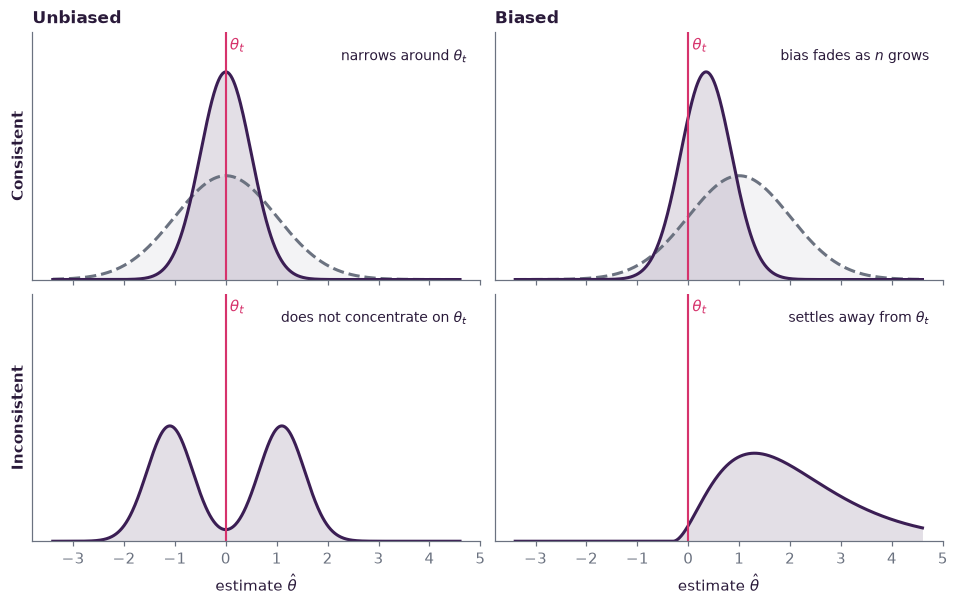

In [4]:
x = np.linspace(-3.4, 4.6, 600)
fig, axes = plt.subplots(2, 2, figsize=(8.6, 5.4), sharex=True, sharey=True, constrained_layout=True)

def panel(ax, curves, note):
    for pdf, style in curves:
        ax.plot(x, pdf(x), color=PLUM if style == "-" else GREY, ls=style, lw=2)
        ax.fill_between(x, pdf(x), color=PLUM if style == "-" else GREY, alpha=0.08 if style == "--" else 0.14, lw=0)
    ax.axvline(0, color=FUCHSIA, lw=1.4)
    ax.text(0.08, 0.93, r"$\theta_t$", color=FUCHSIA, transform=ax.get_xaxis_transform())
    ax.text(0.97, 0.93, note, ha="right", va="top", transform=ax.transAxes, fontsize=9)
    ax.set(yticks=[], ylim=(0, 0.95))

N = stats.norm
panel(axes[0, 0], [(N(0, 1.0).pdf, "--"), (N(0, 0.5).pdf, "-")], "narrows around $\\theta_t$")
panel(axes[0, 1], [(N(1.0, 1.0).pdf, "--"), (N(0.35, 0.5).pdf, "-")], "bias fades as $n$ grows")
bimodal = lambda x: 0.5 * N(-1.1, 0.45).pdf(x) + 0.5 * N(1.1, 0.45).pdf(x)
panel(axes[1, 0], [(bimodal, "-")], "does not concentrate on $\\theta_t$")
skewed = stats.gamma(3, loc=-0.3, scale=0.8).pdf
panel(axes[1, 1], [(skewed, "-")], "settles away from $\\theta_t$")

axes[0, 0].set_title("Unbiased", loc="left")
axes[0, 1].set_title("Biased", loc="left")
axes[0, 0].set_ylabel("Consistent", fontweight="bold")
axes[1, 0].set_ylabel("Inconsistent", fontweight="bold")
axes[1, 0].set_xlabel("estimate $\\hat\\theta$")
axes[1, 1].set_xlabel("estimate $\\hat\\theta$")
plt.show()

### Efficiency

Neglecting the bias, the smaller the variance of the estimator, the more certain we are that the estimate is near the true value. For any consistent estimator the variance has a lower bound:

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Cramér-Rao bound and efficiency**

$$V(\hat\theta) \;\ge\; V_{CR}(\hat\theta) = \frac{\left(1 + \dfrac{\partial b(\hat\theta)}{\partial\theta}\right)^{2}}{E\!\left[\left(\dfrac{\partial\ln\mathcal{L}(\vec{x}\,|\,\theta)}{\partial\theta}\right)^{2}\right]} \qquad\qquad \varepsilon(\hat\theta) = \frac{V_{CR}(\hat\theta)}{V(\hat\theta)}$$

The denominator is the **Fisher information**, evaluated at the true value $\theta$. The efficiency $\varepsilon$ of a consistent estimator is at most 1.

</div>

### Robustness

An estimator is **robust** if it is not much affected by outliers. The median is more robust than the mean:

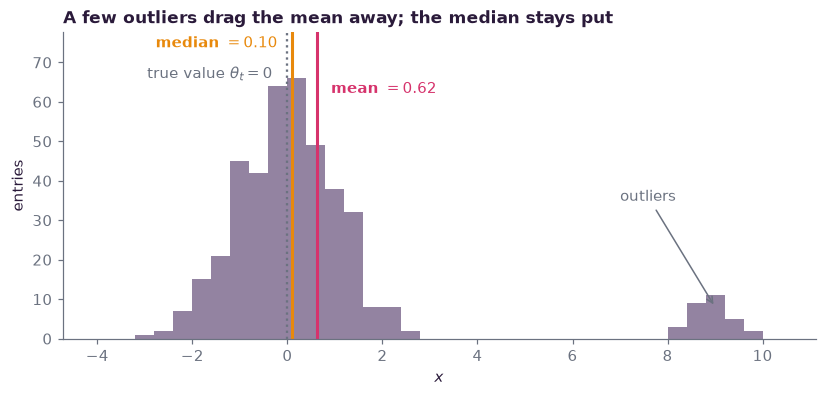

In [5]:
data = np.concatenate([rng.normal(0, 1, 400), rng.normal(9, 0.3, 30)])      # 400 good points + 30 outliers
mean, median = data.mean(), np.median(data)

fig, ax = plt.subplots(figsize=(7.4, 3.5), constrained_layout=True)
ax.hist(data, bins=np.arange(-4, 10.5, 0.4), color=PLUM, alpha=0.55)
ax.axvline(0, color=GREY, ls=":", lw=1.5)
ax.axvline(median, color=AMBER, lw=2)
ax.axvline(mean, color=FUCHSIA, lw=2)
top = ax.get_ylim()[1] * 1.12
ax.set_ylim(0, top)
ax.text(median - 0.3, top * 0.95, rf"median $= {median:.2f}$", color=AMBER, ha="right", fontweight="bold")
ax.text(mean + 0.3, top * 0.80, rf"mean $= {mean:.2f}$", color=FUCHSIA, fontweight="bold")
ax.text(-0.3, top * 0.85, r"true value $\theta_t = 0$", color=GREY, ha="right")
ax.annotate("outliers", xy=(9, 8), xytext=(7.0, top * 0.45), color=GREY, arrowprops=dict(arrowstyle="->", color=GREY))
ax.set(xlabel="$x$", ylabel="entries")
ax.set_title("A few outliers drag the mean away; the median stays put", loc="left")
plt.show()

---
## 3. Maximum likelihood <a id="s3"></a>

The **maximum-likelihood estimate** is the value $\hat\theta$ for which $\mathcal{L}(\vec{x}\,|\,\hat\theta)$ is maximal, given the measured data $\vec{x}$. With $n$ measurements $\vec{x} = \{\vec{x}_1, \dots, \vec{x}_n\}$:

$$\mathcal{L}(\vec{x}\,|\,\vec\theta) = \prod_{i=1}^{n} f(\vec{x}_i\,|\,\vec\theta) \qquad\Longrightarrow\qquad \ln\mathcal{L} = \sum_{i=1}^{n}\ln f(\vec{x}_i\,|\,\vec\theta)$$

From a computational point of view it is better to turn the product $\prod$ into a sum $\sum$ by taking the logarithm; and since the logarithm is monotonic, $\max\mathcal{L} \equiv \max(\ln\mathcal{L})$. Here is a case simple enough to be solved by eye: $n = 12$ lifetimes drawn from an exponential distribution.

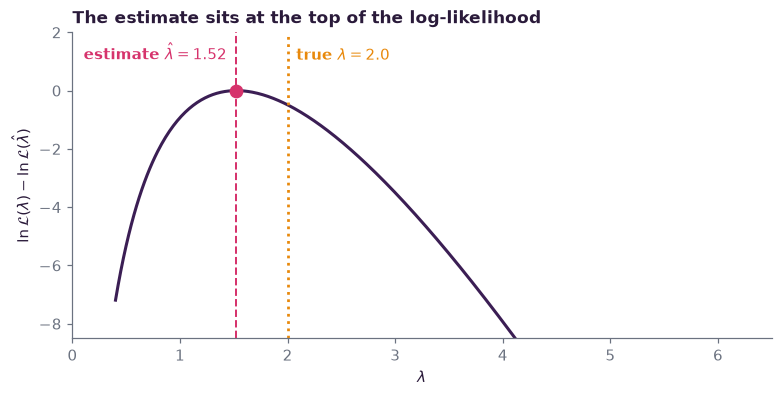

In [6]:
lam_true, n_life = 2.0, 12
x_life = np.random.default_rng(42).exponential(1 / lam_true, n_life)       # fixed seed: a typical draw
lam = np.linspace(0.4, 6.5, 500)
lnL = n_life * np.log(lam) - lam * x_life.sum()                     # ln L(lambda) = n ln(lambda) - lambda * sum(x)
lam_hat = n_life / x_life.sum()

fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.plot(lam, lnL - lnL.max(), color=PLUM)
ax.plot(lam_hat, 0, "o", color=FUCHSIA, ms=8)
ax.axvline(lam_hat, color=FUCHSIA, ls="--", lw=1.3)
ax.axvline(lam_true, color=AMBER, ls=":", lw=1.8)
ax.text(lam_hat - 0.08, 1.05, rf"estimate $\hat\lambda = {lam_hat:.2f}$", color=FUCHSIA, ha="right", fontweight="bold")
ax.text(lam_true + 0.08, 1.05, rf"true $\lambda = {lam_true:.1f}$", color=AMBER, fontweight="bold")
ax.set(xlim=(0, 6.5), ylim=(-8.5, 2.0), xlabel=r"$\lambda$", ylabel=r"$\ln\mathcal{L}(\lambda) - \ln\mathcal{L}(\hat\lambda)$")
ax.set_title("The estimate sits at the top of the log-likelihood", loc="left")
plt.show()

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Properties of maximum-likelihood estimators**

1. Max-$\mathcal{L}$ estimators are **consistent**.
2. They might be **biased**, but $\lim_{n\to\infty} b(\mathcal{L}) = 0$.
3. They are **asymptotically normal** with minimum variance, given by the Cramér-Rao lower bound: $\lim_{n\to\infty}\varepsilon(\mathcal{L}) = 1$.
4. They are **invariant under reparametrization**: if we reparametrize $\theta$ with $\tau(\theta)$, we find $\hat\tau = \tau(\hat\theta)$.

</div>

---
## 4. Extended likelihood <a id="s4"></a>

Suppose we run a measurement for some time and observe $n$ events. Then $n$ is itself a **random variable**, with distribution $P(n\,|\,\vec\theta)$, and the likelihood must be extended to include it. In most cases $P(n|\vec\theta)$ is a Poisson with average $\lambda$:

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Extended likelihood**

$$\mathcal{L} = P(n\,|\,\vec\theta)\prod_{i=1}^{n} f(\vec{x}_i\,|\,\vec\theta) \qquad\Longrightarrow\qquad \mathcal{L} = \frac{e^{-\lambda}\lambda^{n}}{n!}\prod_{i=1}^{n} f(\vec{x}_i\,|\,\vec\theta), \quad \lambda = \lambda(\vec\theta)$$

</div>

With **signal and background**, let $s$ and $b$ be the expectation values of the number of signal and of background events, so $\lambda = s + b$ and

$$f(\vec{x}\,|\,\vec\theta) = \frac{s\,f_s(\vec{x}\,|\,\vec\theta) + b\,f_b(\vec{x}\,|\,\vec\theta)}{s + b}$$

The likelihood and its logarithm become

$$\mathcal{L} = \frac{(s+b)^n\,e^{-(s+b)}}{n!}\prod_{i=1}^{n}\frac{s\,f_s(\vec{x}_i\,|\,\vec\theta) + b\,f_b(\vec{x}_i\,|\,\vec\theta)}{s+b} \qquad \ln\mathcal{L} = -s - b - \ln(n!) + \sum_{i=1}^{n}\ln\big[s\,f_s + b\,f_b\big]$$

where $\ln(n!)$ is a constant, so it does not matter for the maximization.

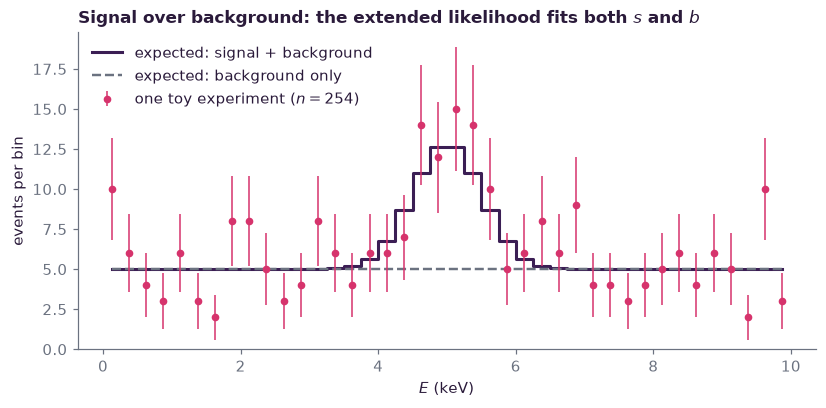

In [7]:
mu, sig, s, b, E_min, E_max = 5.0, 0.5, 40, 200, 0.0, 10.0
edges = np.linspace(E_min, E_max, 41)
centres, width = 0.5 * (edges[1:] + edges[:-1]), edges[1] - edges[0]
exp_s = s * (stats.norm.cdf(edges[1:], mu, sig) - stats.norm.cdf(edges[:-1], mu, sig))
exp_b = np.full_like(centres, b * width / (E_max - E_min))
counts = rng.poisson(exp_s + exp_b)                                   # one toy experiment

fig, ax = plt.subplots(figsize=(7.4, 3.6), constrained_layout=True)
ax.step(centres, exp_s + exp_b, where="mid", color=PLUM, lw=2, label="expected: signal + background")
ax.step(centres, exp_b, where="mid", color=GREY, lw=1.6, ls="--", label="expected: background only")
ax.errorbar(centres, counts, np.sqrt(counts), fmt="o", color=FUCHSIA, ms=4, lw=1, label=f"one toy experiment ($n = {counts.sum()}$)")
ax.set(xlabel="$E$ (keV)", ylabel="events per bin", ylim=(0, None))
ax.set_title(r"Signal over background: the extended likelihood fits both $s$ and $b$", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.show()

---
## 5. Binned likelihood <a id="s5"></a>

Suppose $n$ is so large that computing $\sum_{i}\ln f(\vec{x}_i|\vec\theta)$ takes too long. We can **bin** the data in $m \ll n$ bins. The likelihood is then a multinomial, times the extended term for the total number of events:

$$\mathcal{L} = P(n\,|\,\vec\theta)\;n!\prod_{i=1}^{m}\frac{p_i^{\,k_i}}{k_i!}$$

where $i$ is the **bin** index (not the event index!), $k_i$ is the number of events in bin $i$, $p_i$ the probability associated to bin $i$, and $\sum_i k_i = n$.

If $P(n|\vec\theta)$ is a Poisson with expectation $\lambda = \sum_{i=1}^{m}\lambda_i$, where $\lambda_i = \lambda\int_{\Delta x_i} f(\vec{x}\,|\,\vec\theta)\,d\vec{x}$ is the expected number of events in bin $i$, then $p_i = \lambda_i/\lambda$ and

$$\mathcal{L} = \frac{e^{-\lambda}\lambda^n}{n!}\;n!\prod_{i=1}^{m}\left(\frac{\lambda_i}{\lambda}\right)^{k_i}\frac{1}{k_i!} = e^{-\lambda}\prod_{i=1}^{m}\frac{\lambda_i^{\,k_i}}{k_i!} = \prod_{i=1}^{m}\frac{\lambda_i^{\,k_i}\,e^{-\lambda_i}}{k_i!}$$

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Binned likelihood**

The binned version of an extended $\mathcal{L}$ with a Poisson distribution for $n$ is the **product of a Poisson term for each bin**.

</div>

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercise**

Which one is faster, and when? Compare the extended and the binned likelihood.

- [Extended vs binned likelihood](../exercises/03_point_estimation/ex01_extended_vs_binned_likelihood.ipynb)

</div>

---
## 6. The $\chi^2$ (least squares) method <a id="s6"></a>

Consider a set of measurements with Gaussian uncertainties $y_i \pm \sigma_i$ at points $x_i$, and a model $y = y(x, \vec\theta)$. Assume the uncertainty on $x_i$ is negligible. The likelihood of the data is (a function, not a PDF)

$$\mathcal{L}(\vec{y}, \vec\sigma\,|\,\vec\theta) = \prod_{i=1}^{n}\frac{1}{\sqrt{2\pi}\,\sigma_i}\exp\!\left(-\frac{\big(y_i - y(x_i;\vec\theta)\big)^2}{2\sigma_i^2}\right)$$

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Least squares**

$$-2\ln\mathcal{L} = \sum_{i=1}^{n}\frac{\big(y_i - y(x_i;\vec\theta)\big)^2}{\sigma_i^2} + \underbrace{\sum_{i=1}^{n}\ln\!\big(2\pi\sigma_i^2\big)}_{\text{does not depend on }\vec\theta\ \Rightarrow\ \text{constant}} \qquad\Longrightarrow\qquad \chi^2 \simeq -2\ln\mathcal{L} = \sum_{i=1}^{n}\frac{\big(y_i - y(x_i;\hat{\vec\theta})\big)^2}{\sigma_i^2}$$

The first term is a sum of squared standard normal variables, hence a $\chi^2$ distribution, **only if $\vec\theta$ is known**. If $\vec\theta$ is unknown, the set of $\vec\theta$ values that minimizes $-2\ln\mathcal{L}$ provides a $\chi^2$ distribution (with $n - \dim\vec\theta$ degrees of freedom) if all the $y_i$ are uncorrelated.

</div>

If the $y_i$ are not normally distributed, or are correlated, or if $y(x, \vec\theta)$ does not describe the data perfectly, least squares still estimates the parameters, but it will not behave as a $\chi^2$: and that can actually be used to test the goodness of fit.

Always look at the fit, its **residuals** and its **pulls**. Residuals keep the units of $y$; pulls divide by the uncertainty, so every point weighs the same:

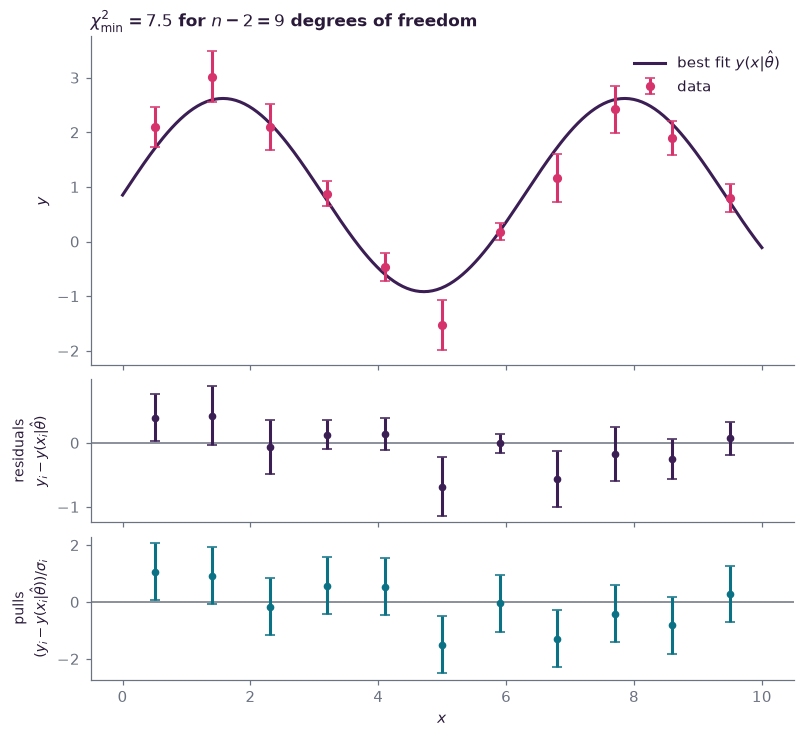

In [8]:
from scipy.optimize import curve_fit

rng3 = np.random.default_rng(7)
model = lambda x, A, B: A * np.sin(x) + B
x = np.linspace(0.5, 9.5, 11)
sigma = rng3.uniform(0.15, 0.5, x.size)
y = model(x, 2.0, 1.0) + rng3.normal(0, sigma)
popt, _ = curve_fit(model, x, y, sigma=sigma, absolute_sigma=True)
res = y - model(x, *popt)
chi2 = np.sum((res / sigma) ** 2)
xx = np.linspace(0, 10, 300)

fig, axes = plt.subplots(3, 1, figsize=(7.2, 6.6), sharex=True, gridspec_kw=dict(height_ratios=[2.3, 1, 1]), constrained_layout=True)
axes[0].plot(xx, model(xx, *popt), color=PLUM, label=r"best fit $y(x|\hat{\theta})$")
axes[0].errorbar(x, y, sigma, fmt="o", color=FUCHSIA, ms=5, capsize=3, label="data")
axes[0].set_ylabel("$y$")
axes[0].legend(frameon=False, loc="upper right")
axes[0].set_title(rf"$\chi^2_{{\min}} = {chi2:.1f}$ for $n - 2 = {x.size - 2}$ degrees of freedom", loc="left")
axes[1].axhline(0, color=GREY, lw=1)
axes[1].errorbar(x, res, sigma, fmt="o", color=PLUM, ms=4, capsize=3)
axes[1].set_ylabel(r"residuals" "\n" r"$y_i - y(x_i|\hat{\theta})$", fontsize=9)
axes[2].axhline(0, color=GREY, lw=1)
axes[2].errorbar(x, res / sigma, 1, fmt="o", color=TEAL, ms=4, capsize=3)
axes[2].set_ylabel(r"pulls" "\n" r"$(y_i - y(x_i|\hat{\theta}))/\sigma_i$", fontsize=9)
axes[2].set_xlabel("$x$")
plt.show()

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercises**

Does the minimum $\chi^2$ really follow a $\chi^2$ distribution? And what happens when the uncertainties are overestimated, or when the model misses a systematic effect?

- [Scatter plot ($\chi^2$ fit)](../exercises/03_point_estimation/ex02_scatter_plot_chi2_fit.ipynb)
- [Scatter plot $\chi^2$ fit with overestimated uncertainty](../exercises/03_point_estimation/ex03_overestimated_uncertainty.ipynb)
- [Scatter plot $\chi^2$ fit with unaccounted systematic](../exercises/03_point_estimation/ex04_unaccounted_systematic.ipynb)

</div>

---
## 7. Fitting histograms <a id="s7"></a>

Least squares for fitting histograms: **can I use it? Yes. Should I use it? No.** Let's see why.

Historically, computing power was not enough to maximize $\mathcal{L}$ numerically, especially with factorials, while minimizing a sum of squares was easy. That is how least squares came to be applied to histograms.

Take measurements $x_i$ with PDF $f(x_i|\vec\theta)$, bin the data, and assume that every bin has a very large number of events $k_i$, so that $\text{Poisson}(k_i) \sim \text{Gauss}(k_i)$. Let $\lambda$ be the expected total number of events and $\lambda_i = \lambda\int_{\Delta x_i} f(x|\vec\theta)\,dx$ the expected number in bin $i$. Then

$$-2\ln\mathcal{L} \simeq \chi^2 = \sum_{i=1}^{m}\frac{\big(k_i - \lambda_i(\vec\theta)\big)^2}{\sigma_i^2}$$

(the term $\sum_i \ln(2\pi\sigma_i^2)$ is constant for this purpose). But what is $\sigma_i$? There are two possible choices:

<div style="border-left: 6px solid #e8890c; background: #fff3dc; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**▲ Two choices, two problems**

**1. Neyman's $\chi^2$:** $\sigma_i^2 = k_i$, the *measured* number of events in the bin.

$$\chi^2_N = \sum_{i=1}^{m}\frac{\big(k_i - \lambda_i(\vec\theta)\big)^2}{k_i}$$

It is the default in ROOT-Minuit, and it **fails miserably with empty bins**.

**2. Pearson's $\chi^2$:** $\sigma_i^2 = \lambda_i$, the *expected* number of events in the bin.

$$\chi^2_P = \sum_{i=1}^{m}\frac{\big(k_i - \lambda_i(\vec\theta)\big)^2}{\lambda_i(\vec\theta)}$$

It **introduces a bias**.

</div>

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ The way out**

Use the **likelihood on histograms**: the product of a Poisson term for each bin.

</div>

<div style="border-left: 6px solid #3b1e54; background: #f0e9f7; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**✎ Exercises**

Put the three methods side by side on binned Poisson data, and on an efficiency curve.

- [Likelihood vs $\chi^2$ for binned Poisson data](../exercises/03_point_estimation/ex05_likelihood_vs_chi2_binned.ipynb)
- [Efficiency curve fit with binomial $\mathcal{L}$, Poisson $\mathcal{L}$ and Gaussian $\chi^2$](../exercises/03_point_estimation/ex06_efficiency_curve_fit.ipynb)

</div>

---
## 8. In practice <a id="s8"></a>

How do we minimize a $\chi^2$ or maximize an $\mathcal{L}$? Every language has tools; the trouble starts when you want to tweak the function for precision or speed.

| Tool | What it offers |
|:--|:--|
| **ROOT** (Minuit), C++ and Python | $\chi^2$ fit available for scatter plots (`TGraphErrors`) · default $\chi^2_N$ for histograms · $\chi^2_P$ with the option `"P"` · Poisson $\mathcal{L}$ on histograms with the option `"L"` · a custom $\mathcal{L}$ is possible, but complicated |
| **BAT** (Bayesian Analysis Toolkit), C++ and ROOT | A framework for Bayesian fits that can be forced to perform frequentist ones: implement your $\mathcal{L}$, then call `model->FindMode()` to run the underlying ROOT fitter. The suggestion if you want ROOT + C++ |
| **numpy + scipy.optimize**, Python | Easy to define a custom $\mathcal{L}$ and pass it to `minimize` |
| **Julia** | A minimizer is available from the `Optim` package, and it can minimize a custom $\mathcal{L}$ |

For instance, here is the lifetime example of section 3, with a custom $\mathcal{L}$ handed to `minimize`:

In [9]:
from scipy.optimize import minimize

neg_lnL = lambda p: -(n_life * np.log(p[0]) - p[0] * x_life.sum())       # custom -ln L
result = minimize(neg_lnL, x0=[1.0], bounds=[(1e-6, None)])
print(f"minimizer: {result.x[0]:.4f}   analytic n / sum(x): {n_life / x_life.sum():.4f}")

minimizer: 1.5225   analytic n / sum(x): 1.5225


<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**★ What to remember**

- **Inference connects model and data:** an estimator turns data into a central value for a parameter.
- **A good estimator is** consistent, (nearly) unbiased, efficient (it saturates the Cramér-Rao bound) and robust.
- **Maximum likelihood** is consistent, asymptotically unbiased, asymptotically efficient, and invariant under reparametrization. Maximize $\ln\mathcal{L}$: a sum is easier than a product.
- **Extended** likelihood adds the Poisson term for the number of events; **binned** likelihood is a product of Poisson terms, one per bin.
- **$\chi^2$ is a likelihood in disguise** (Gaussian errors, constant dropped). On histograms, Neyman's version fails with empty bins and Pearson's is biased: use the likelihood.

</div>